<center><h1>HW5</h1></center>
<br>
<br>

Name: Minhao Zou
<br>
Github Username: zmh0917
<br>
USC ID: 6793831877

## 1. Decision Trees as Interpretable Models

Import packages

In [1]:
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.tree import DecisionTreeClassifier, plot_tree, _tree
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.decomposition import PCA
from xgboost import XGBRegressor

### (a) Obtain Data

Get the Accute Inamations Data Set

In [2]:
columns = ["Temperature","Nausea","Lumbar pain", "Urine pushing", "Micturition pains","Urethra burning","Bladder inflammation","Nephritis"]
df = pd.read_csv(
    Path("data") / "diagnosis.data",
    sep="\t",
    header=None,
    encoding="utf-16",
    decimal=",",
    names=columns
)

for column in columns[1:]:
    df[column] = (df[column].str.strip().map({"no": 0, "yes": 1}))
X = df[columns[:6]].copy()
y = 2*df["Bladder inflammation"]+df["Nephritis"]

print(df.shape)
print(df.isna().sum().sum())
print(y.value_counts().sort_index())

display(df.head())

(120, 8)
0
0    30
1    31
2    40
3    19
Name: count, dtype: int64


,Temperature,Nausea,Lumbar pain,Urine pushing,Micturition pains,Urethra burning,Bladder inflammation,Nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

train accuracy: 1.0
depth: 4
leaves num: 6


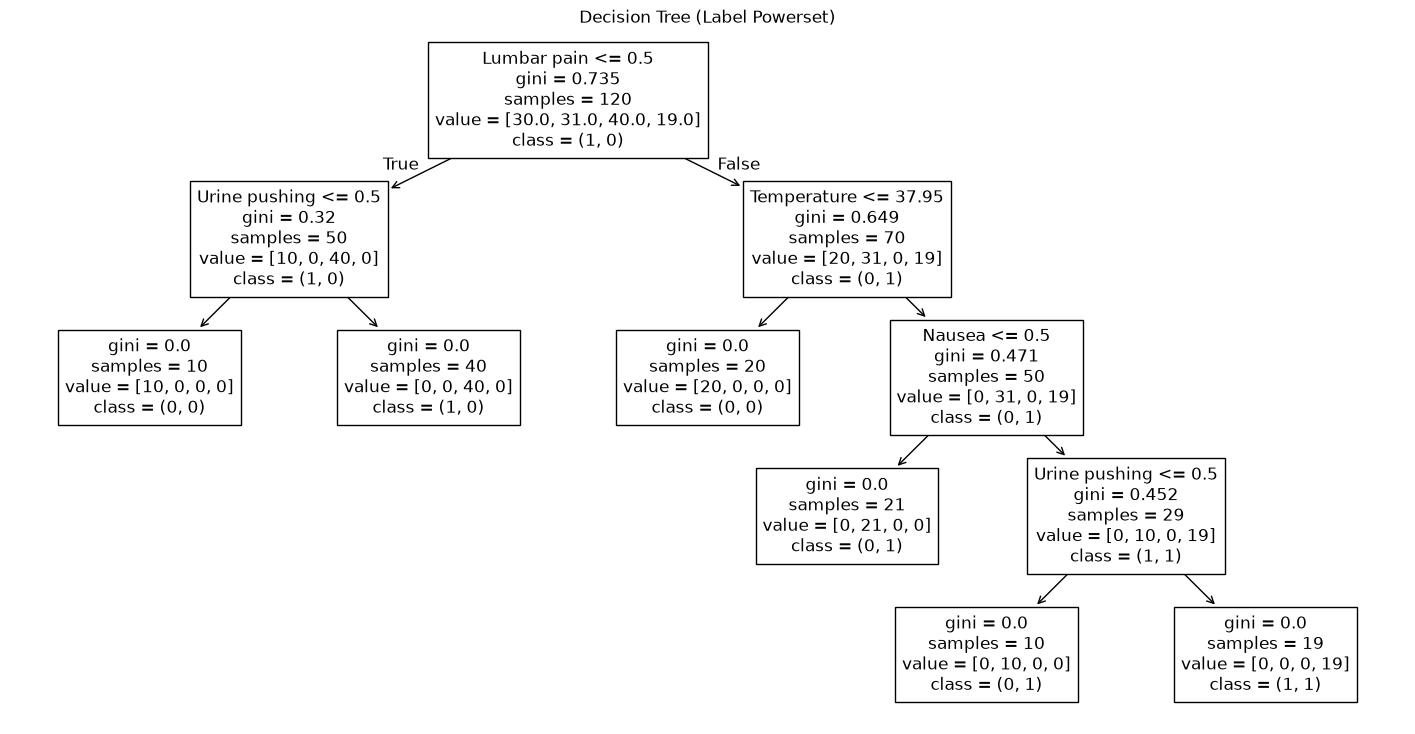

In [3]:
tree_model = DecisionTreeClassifier(random_state=42)
tree_model.fit(X, y)
y_pred = tree_model.predict(X)

print("train accuracy:", accuracy_score(y, y_pred))
print("depth:", tree_model.get_depth())
print("leaves num:", tree_model.get_n_leaves())

labels = {
    0: "(0, 0)",
    1: "(0, 1)",
    2: "(1, 0)",
    3: "(1, 1)"
}
class_names = [labels[k] for k in tree_model.classes_]
plt.figure(figsize=(18, 9))
plot_tree(
    tree_model,
    feature_names=list(X.columns),
    class_names=class_names,
)
plt.title("Decision Tree (Label Powerset)")
plt.show()

### (c) Convert the decision rules

In [ ]:
def print_rules(model, names):
    tree = model.tree_
    def visit(node, path):
        if tree.feature[node] == _tree.TREE_UNDEFINED:
            values = tree.value[node][0]
            index = np.argmax(values)
            label = int(model.classes_[index])
            bladder = label // 2
            nephritis = label % 2
            rule = " AND ".join(path) if path else "TRUE"
            print(
                f"IF {rule} THEN "
                f"Bladder inflammation={bladder}, Nephritis={nephritis}"
            )
            return

        feature = names[tree.feature[node]]
        threshold = tree.threshold[node]
        visit(tree.children_left[node], path+[f"{feature} <= {threshold:.2f}"])
        visit(tree.children_right[node],path+[f"{feature} > {threshold:.2f}"])
    visit(0, [])

print_rules(tree_model, list(X.columns))

IF Lumbar pain <= 0.50 AND Urine pushing <= 0.50 THEN Bladder inflammation=0, Nephritis=0
IF Lumbar pain <= 0.50 AND Urine pushing > 0.50 THEN Bladder inflammation=1, Nephritis=0
IF Lumbar pain > 0.50 AND Temperature <= 37.95 THEN Bladder inflammation=0, Nephritis=0
IF Lumbar pain > 0.50 AND Temperature > 37.95 AND Nausea <= 0.50 THEN Bladder inflammation=0, Nephritis=1
IF Lumbar pain > 0.50 AND Temperature > 37.95 AND Nausea > 0.50 AND Urine pushing <= 0.50 THEN Bladder inflammation=0, Nephritis=1
IF Lumbar pain > 0.50 AND Temperature > 37.95 AND Nausea > 0.50 AND Urine pushing > 0.50 THEN Bladder inflammation=1, Nephritis=1


### (d) Use cost-complexity pruning to find a minimal decision tree and a set of decision rules with high interpretability.

In [9]:
path = tree_model.cost_complexity_pruning_path(X, y)
alphas = np.unique(path.ccp_alphas)

rows = []
for alpha in alphas:
    model = DecisionTreeClassifier(
        random_state=42,
        ccp_alpha=alpha
    )
    model.fit(X, y)
    pred = model.predict(X)
    rows.append({
        "Alpha": alpha,
        "Depth": model.get_depth(),
        "Leaves": model.get_n_leaves(),
        "Acc": accuracy_score(y, pred)
    })

table = pd.DataFrame(rows)
display(table.round(6))

,Alpha,Depth,Leaves,Acc
0,0.000000,4,6,1.000000
1,0.098167,2,4,0.841667
2,0.133333,2,3,0.758333
3,0.182000,1,2,0.591667
4,0.222917,0,1,0.333333


alpha: 0.098167
depth: 2
leaves num: 4
train acc: 84.17%


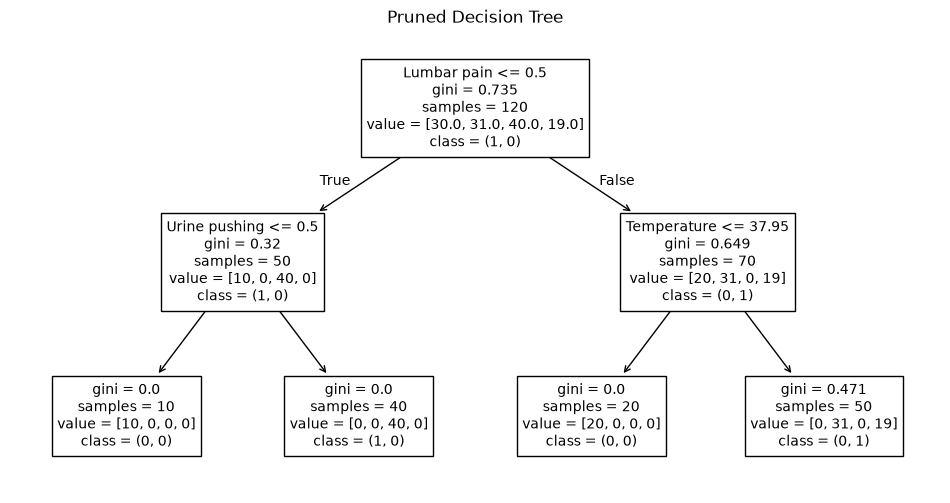

IF Lumbar pain <= 0.50 AND Urine pushing <= 0.50 THEN Bladder inflammation=0, Nephritis=0
IF Lumbar pain <= 0.50 AND Urine pushing > 0.50 THEN Bladder inflammation=1, Nephritis=0
IF Lumbar pain > 0.50 AND Temperature <= 37.95 THEN Bladder inflammation=0, Nephritis=0
IF Lumbar pain > 0.50 AND Temperature > 37.95 THEN Bladder inflammation=0, Nephritis=1


In [8]:
alpha = alphas[1]
pruned = DecisionTreeClassifier(
    random_state=42,
    ccp_alpha=alpha
)
pruned.fit(X, y)
pred = pruned.predict(X)

print(f"alpha: {alpha:.6f}")
print("depth:", pruned.get_depth())
print("leaves num:", pruned.get_n_leaves())
print(f"train acc: {accuracy_score(y, pred):.2%}")

plt.figure(figsize=(12, 6))
plot_tree(
    pruned,
    feature_names=list(X.columns),
    class_names=class_names,
)
plt.title("Pruned Decision Tree")
plt.show()

print_rules(pruned, list(X.columns))

choose the second alpha value in the table, approximately 0.098167

After pruning, the tree depth decreases from 4 to 2, and the number of leaves decreases from 6 to 4. The training accuracy drops from 100% to 84.17%

now have only four rules, each with two conditions

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [10]:
names = []
with open(Path("data")/"communities.names", encoding="utf-8") as f:
    for line in f:
        if line.strip().startswith("@attribute"):
            names.append(line.split()[1])

crime = pd.read_csv(
    Path("data")/"communities.data",
    header=None,
    names=names,
    na_values="?"
)

train = crime.iloc[:1495].copy()
test = crime.iloc[1495:].copy()
print(crime.shape)
print(train.shape)
print(test.shape)
display(crime.head())

(1994, 128)
(1495, 128)
(499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [ ]:
unused = ["state", "county", "community", "communityname", "fold"]
target = "ViolentCrimesPerPop"

X_train = train.drop(columns=unused+[target])
X_test = test.drop(columns=unused+[target])
y_train = train[target].copy()
y_test = test[target].copy()

print(X_train.shape)
print(X_test.shape)
print("missing val in training:", X_train.isna().sum().sum())
print("missing val in test:", X_test.isna().sum().sum())

(1495, 122)
(499, 122)
Missing val in training: 27633
Missing val in test: 9218


In [ ]:
imputer = SimpleImputer(strategy="median")
train_fill = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
test_fill = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)
print("train missing:", train_fill.isna().sum().sum())
print("test missing:", test_fill.isna().sum().sum())

train: 0
test: 0


### (c) Plot a correlation matrix

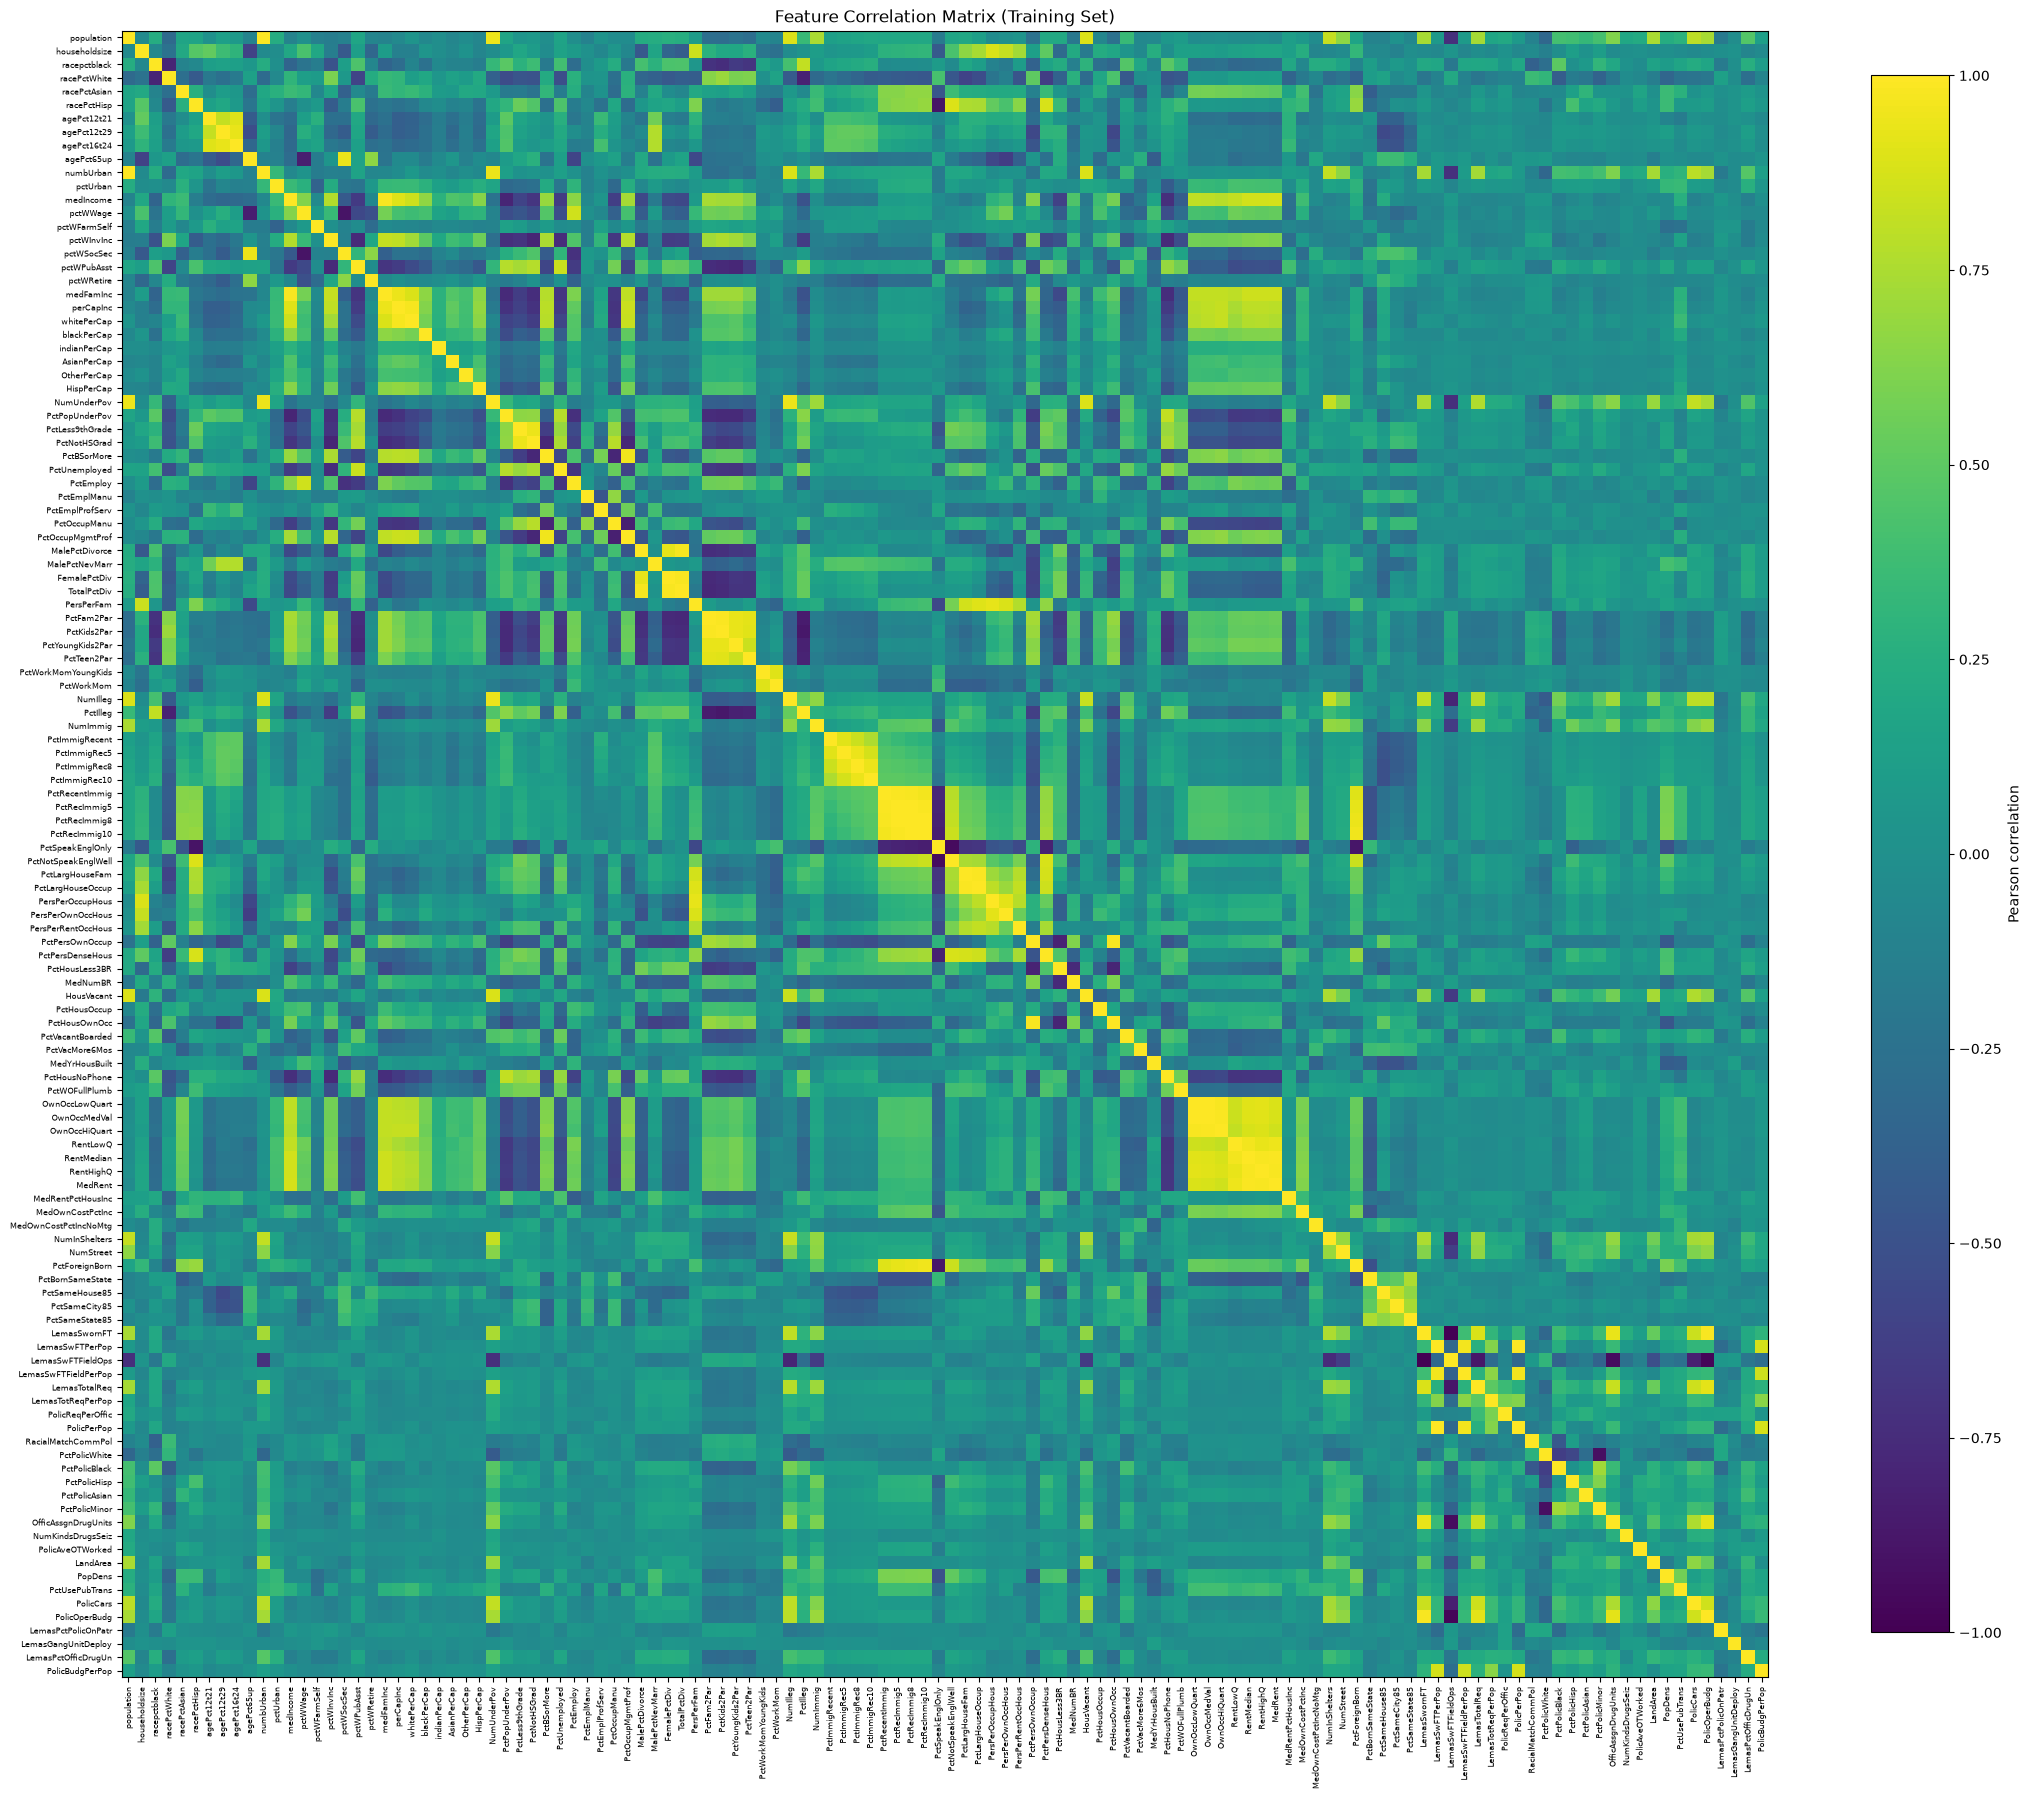

In [13]:
corr = train_fill.corr()
plt.figure(figsize=(22, 20))
image = plt.imshow(
    corr,
    vmin=-1,
    vmax=1,
    interpolation="nearest"
)
plt.colorbar(image, label="Pearson correlation", shrink=0.8)
plt.xticks(
    range(len(corr)),
    corr.columns,
    rotation=90,
    fontsize=6
)
plt.yticks(
    range(len(corr)),
    corr.index,
    fontsize=6
)
plt.title("Feature Correlation Matrix (Training Set)")
plt.tight_layout()
plt.show()
# plotting assist by GPT

### (d) Calculate the Coefficient of Variation CV

In [16]:
mean = train_fill.mean()
std = train_fill.std(ddof=1)
cv = std / mean.replace(0, np.nan)

cv_table = pd.DataFrame({
    "Mean": mean,
    "Std": std,
    "CV": cv
}).sort_values("CV", ascending=False)

with pd.option_context("display.max_rows", None):
    display(cv_table.round(6))

,Mean,Std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


### (e) Scatter plots and box plots for highest CV features

In [17]:
k = int(np.sqrt(128))
top = cv_table["CV"].dropna().head(k).index.tolist()
display(cv_table.loc[top].round(6))

,Mean,Std,CV
PctPolicAsian,0.016254,0.089838,5.527059
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
LemasSwornFT,0.028749,0.064629,2.248042
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461


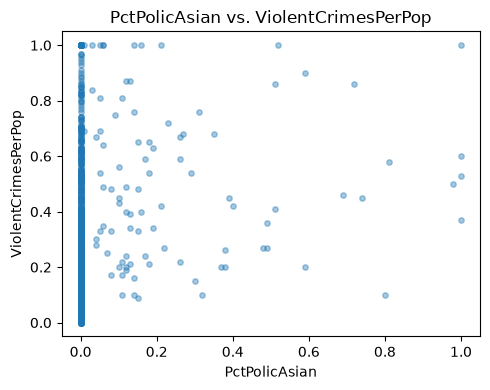

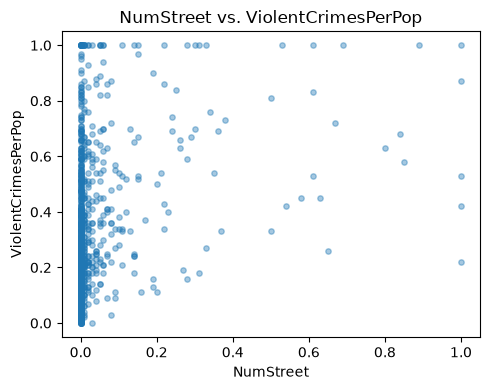

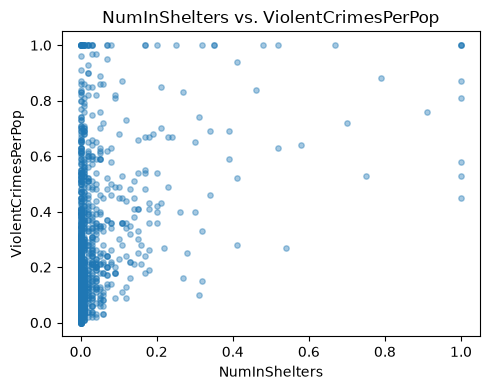

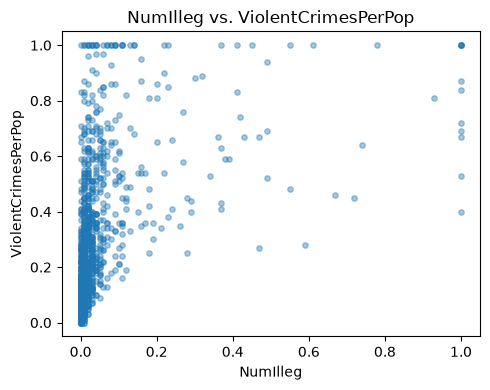

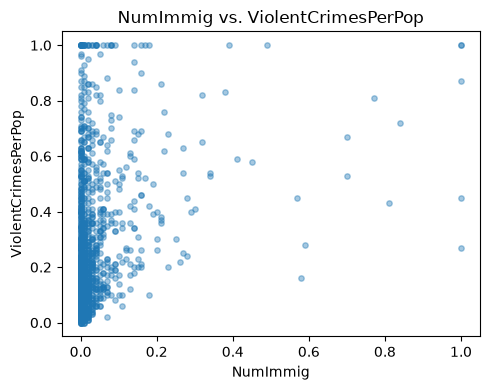

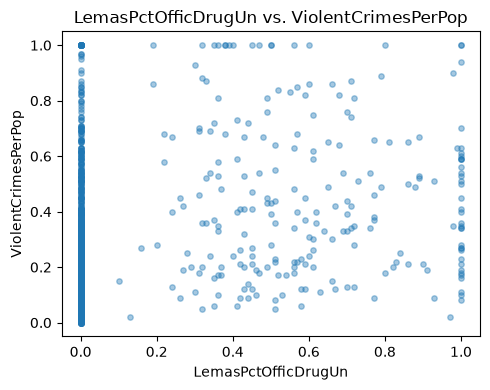

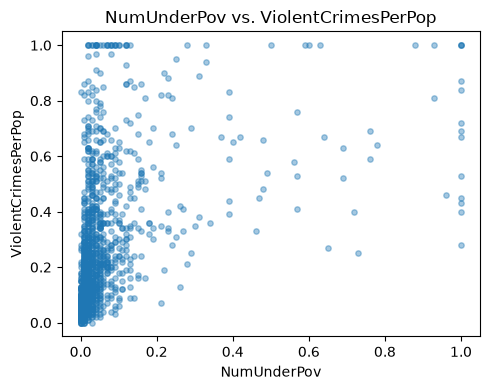

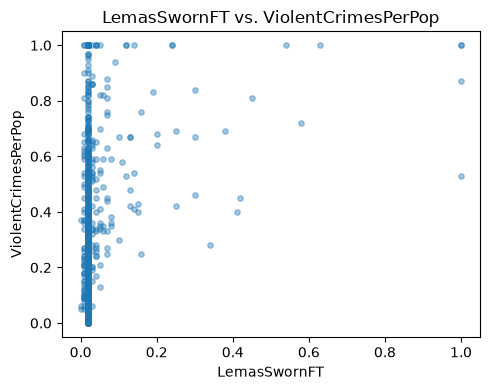

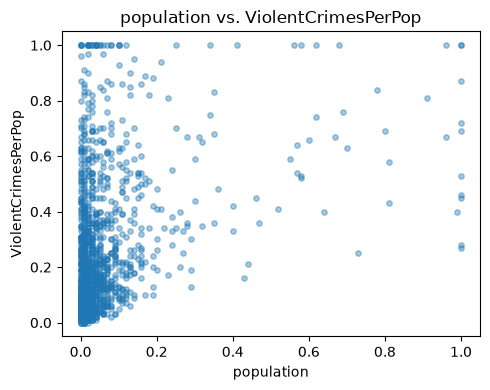

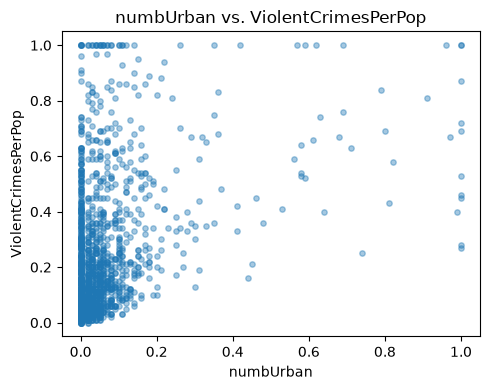

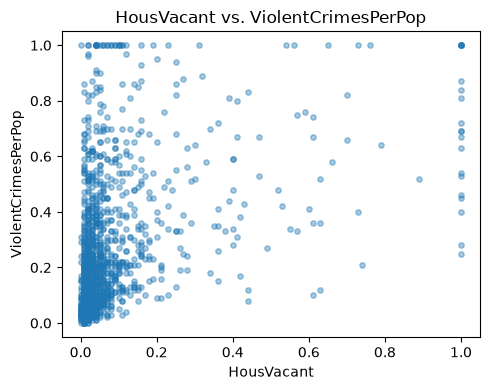

In [18]:
for name in top:
    plt.figure(figsize=(5, 4))
    plt.scatter(
        train_fill[name],
        y_train,
        s=15,
        alpha=0.4
    )
    plt.xlabel(name)
    plt.ylabel(target)
    plt.title(f"{name} vs. {target}")
    plt.tight_layout()
    plt.show()

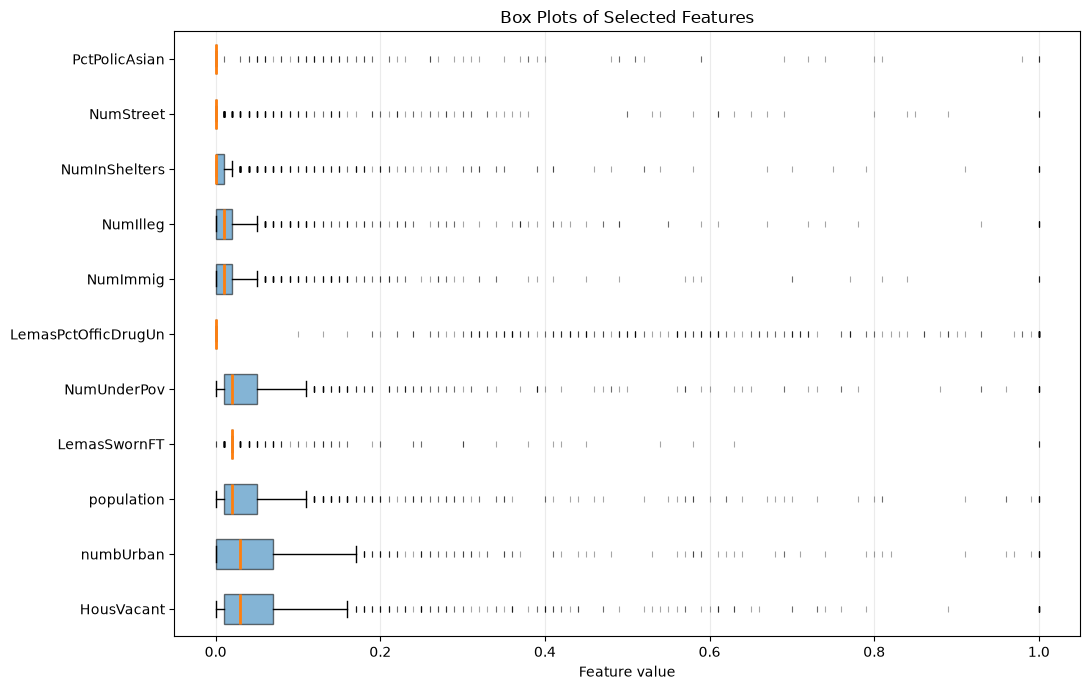

In [ ]:
data = [train_fill[name].to_numpy() for name in top]
plt.figure(figsize=(11, 7))
plt.boxplot(
    data,
    orientation="horizontal",
    tick_labels=top,
    showfliers=True,
    flierprops={
        "marker": "|",
        "markersize": 5,
        "markeredgewidth": 0.8,
        "alpha": 0.35,
        "linestyle": "none"
    },
    patch_artist=True,
    widths=0.55,
    boxprops={"alpha": 0.55},
    medianprops={"linewidth": 2}
)

plt.gca().invert_yaxis()
plt.gca().set_axisbelow(True)

plt.xlabel("Feature value")
plt.title("Box Plots of Selected Features")
plt.yticks(fontsize=10)
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()
# plotting assist by GPT

No. The scatter plots may show relationships between the features and the target, but cannot tell whether these relationships are statistically significant from the plots alone

Still need an appropriate statistical test to draw that conclusion.

### (f) Fit a linear model

In [29]:
ols = LinearRegression()
ols.fit(train_fill, y_train)
pred = ols.predict(test_fill)
mse_ols = mean_squared_error(y_test, pred)

print(f"Test MSE: {mse_ols:.8f}")

Test MSE: 0.01796622


### (g) Fit a ridge regression model

In [30]:
method = imputer.strategy
folds = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
pipe = Pipeline([
    ("fill", SimpleImputer(strategy=method)),
    ("scale", StandardScaler()),
    ("model", Ridge())
])

params = {"model__alpha": np.logspace(-4, 4, 81)}
ridge = GridSearchCV(
    pipe,
    param_grid=params,
    scoring="neg_mean_squared_error",
    cv=folds,
    n_jobs=-1
)
ridge.fit(X_train, y_train)
pred = ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, pred)

print("Best alpha:", ridge.best_params_["model__alpha"])
print(f"CV MSE: {-ridge.best_score_:.8f}")
print(f"Test MSE: {mse_ridge:.8f}")

Best alpha: 125.89254117941688
CV MSE: 0.01973765
Test MSE: 0.01737249


slightly lower than the test MSE of ordinary linear regression

### (h) Fit a LASSO model

In [31]:
# without additional standardization
pipe = Pipeline([
    ("fill", SimpleImputer(strategy=method)),
    ("model", Lasso(max_iter=100000, tol=1e-6))
])
params = {"model__alpha": np.logspace(-5, 0, 51)}
lasso = GridSearchCV(
    pipe,
    param_grid=params,
    scoring="neg_mean_squared_error",
    cv=folds,
    n_jobs=-1
)
lasso.fit(X_train, y_train)
pred = lasso.predict(X_test)
mse_lasso = mean_squared_error(y_test, pred)

print("Best alpha:", lasso.best_params_["model__alpha"])
print(f"CV MSE: {-lasso.best_score_:.8f}")
print(f"Test MSE: {mse_lasso:.8f}")

model = lasso.best_estimator_.named_steps["model"]
coef = pd.Series(
    model.coef_,
    index=X_train.columns,
    name="Coefficient"
)
keep = coef[coef.abs() > 1e-8]
print("Number of selected variables:", len(keep))
with pd.option_context("display.max_rows", None):
    display(keep.to_frame())

Best alpha: 0.00012589254117941674
CV MSE: 0.01952050
Test MSE: 0.01761464
Number of selected variables: 74


,Coefficient
racepctblack,0.267088
racePctAsian,-0.014234
agePct12t21,0.057859
agePct12t29,-0.246633
pctUrban,0.040552
pctWWage,-0.076896
pctWFarmSelf,0.025244
pctWInvInc,-0.096621
pctWSocSec,0.047017
pctWPubAsst,0.038210


standardized

In [ ]:
pipe = Pipeline([
    ("fill", SimpleImputer(strategy=method)),
    ("scale", StandardScaler()),
    ("model", Lasso(max_iter=100000, tol=1e-6))
])
scaled = GridSearchCV(
    pipe,
    param_grid=params,
    scoring="neg_mean_squared_error",
    cv=folds,
    n_jobs=-1
)
scaled.fit(X_train, y_train)
pred = scaled.predict(X_test)
mse_scaled = mean_squared_error(y_test, pred)

print("Best alpha:", scaled.best_params_["model__alpha"])
print(f"CV MSE: {-scaled.best_score_:.8f}")
print(f"Test MSE: {mse_scaled:.8f}")

model = scaled.best_estimator_.named_steps["model"]
coef_std = pd.Series(
    model.coef_,
    index=X_train.columns,
    name="Coefficient"
)
keep_std = coef_std[coef_std.abs() > 1e-8]
print("Number of selected variables:", len(keep_std))
with pd.option_context("display.max_rows", None):
    display(keep_std.to_frame())
# standardized assist by gpt

Best alpha: 0.000630957344480193
CV MSE: 0.01966094
Test MSE: 0.01772175
Number of selected variables: 76


,Coefficient
racepctblack,0.068005
racePctAsian,-0.001863
agePct12t21,0.012487
agePct12t29,-0.043304
pctUrban,0.017131
pctWWage,-0.014238
pctWFarmSelf,0.004848
pctWInvInc,-0.022143
pctWSocSec,0.010405
pctWPubAsst,0.007915


In [33]:
table = pd.DataFrame({
    "Model": ["LASSO", "LASSO (standardized)"],
    "Alpha": [
        lasso.best_params_["model__alpha"],
        scaled.best_params_["model__alpha"]
    ],
    "Selected variables": [len(keep), len(keep_std)],
    "Test MSE": [mse_lasso, mse_scaled]
})

display(table.round(8))

,Model,Alpha,Selected variables,Test MSE
0,LASSO,0.000126,74,0.017615
1,LASSO (standardized),0.000631,76,0.017722


Without standardization, LASSO selects 74 variables and gives a test MSE of 0.01761464. After standardization, it selects 76 variables and gives a test MSE of 0.01772175. 

model without standardization performs slightly better on the test set, but the difference is small.

### (i) Fit a PCR model

In [ ]:
pipe = Pipeline([
    ("fill", SimpleImputer(strategy=method)),
    ("scale", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("model", LinearRegression())
])
params = {"pca__n_components": list(range(1, X_train.shape[1]+1))}
pcr = GridSearchCV(
    pipe,
    param_grid=params,
    scoring="neg_mean_squared_error",
    cv=folds,
    n_jobs=-1
)
pcr.fit(X_train, y_train)

M = pcr.best_params_["pca__n_components"]
pred = pcr.predict(X_test)
mse_pcr = mean_squared_error(y_test, pred)

print("Best number of components:", M)
print(f"CV MSE: {-pcr.best_score_:.8f}")
print(f"Test MSE: {mse_pcr:.8f}")

Best number of components: 60
CV MSE: 0.02020950
Test MSE: 0.01834953


use 5-fold cross-validation to choose the number of principal components

The lowest CV MSE is obtained with 60 components

fit the PCR model on the training set using these components and obtain a test MSE of 0.01834953.

### (j) Fit a boosting tree

In [ ]:
pipe = Pipeline([
    ("fill", SimpleImputer(strategy=method)),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        tree_method="hist",
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=1
    ))
])

alphas = np.concatenate(([0.0], np.logspace(-4, 2, 25)))
params = {"model__reg_alpha": alphas}
boost = GridSearchCV(
    pipe,
    param_grid=params,
    scoring="neg_mean_squared_error",
    cv=folds,
    n_jobs=-1,
    verbose=2,
    pre_dispatch=2,
    error_score="raise"
)
boost.fit(X_train, y_train)
alpha = boost.best_params_["model__reg_alpha"]
pred = boost.predict(X_test)
mse_boost = mean_squared_error(y_test, pred)
# GPT assist with troubleshoot the XGBoost grid search by suggesting fewer parallel jobs and adding progress output.
print(f"Best alpha: {alpha:.6g}")
print(f"CV MSE: {-boost.best_score_:.8f}")
print(f"Test MSE: {mse_boost:.8f}")

Fitting 5 folds for each of 26 candidates, totalling 130 fits
[CV] END ...............................model__reg_alpha=0.0; total time=   1.6s
[CV] END ...............................model__reg_alpha=0.0; total time=   1.6s
[CV] END ...............................model__reg_alpha=0.0; total time=   1.0s
[CV] END ...............................model__reg_alpha=0.0; total time=   1.0s
[CV] END ...............................model__reg_alpha=0.0; total time=   1.0s
[CV] END ............................model__reg_alpha=0.0001; total time=   1.0s
[CV] END ............................model__reg_alpha=0.0001; total time=   1.2s
[CV] END ............................model__reg_alpha=0.0001; total time=   1.2s
[CV] END ............................model__reg_alpha=0.0001; total time=   1.2s
[CV] END ............................model__reg_alpha=0.0001; total time=   1.2s
[CV] END ............model__reg_alpha=0.00017782794100389227; total time=   2.0s
[CV] END ............model__reg_alpha=0.0001778

use XGBoost and choose the L1 regularization parameter by 5-fold cross-validation

with other parameters fixed, the selected alpha is 0.1

mean CV MSE is 0.01990737, test MSE is 0.01642190

XGBoost has the lowest test MSE among these models

## honor code
All codes completed with AI assistance have been identified in the comments